Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8949 - loss: 0.3812 - val_accuracy: 0.9568 - val_loss: 0.1740
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9499 - loss: 0.1762 - val_accuracy: 0.9672 - val_loss: 0.1218
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9643 - loss: 0.1236 - val_accuracy: 0.9710 - val_loss: 0.1032
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9728 - loss: 0.0955 - val_accuracy: 0.9720 - val_loss: 0.0904
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9774 - loss: 0.0769 - val_accuracy: 0.9747 - val_loss: 0.0888
Model 1 training completed!
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9180 - loss: 0.2862 - val_accuracy: 0.9675 - val_loss: 0.1111
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9671 - loss: 0.1075 - val_accuracy: 0.9758 - val_loss: 0.0806
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.9781 - los

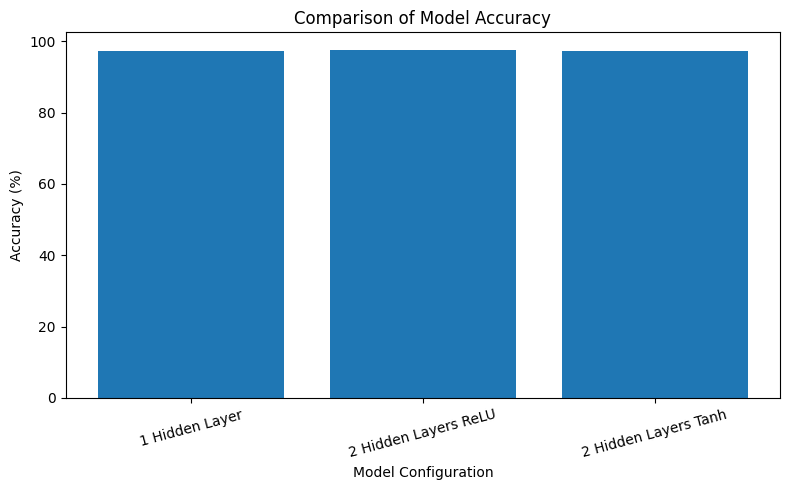

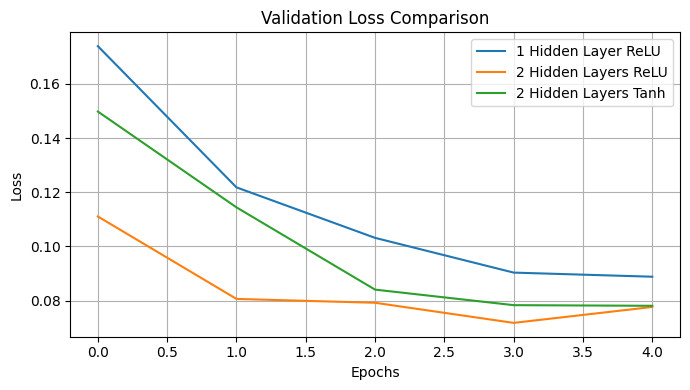

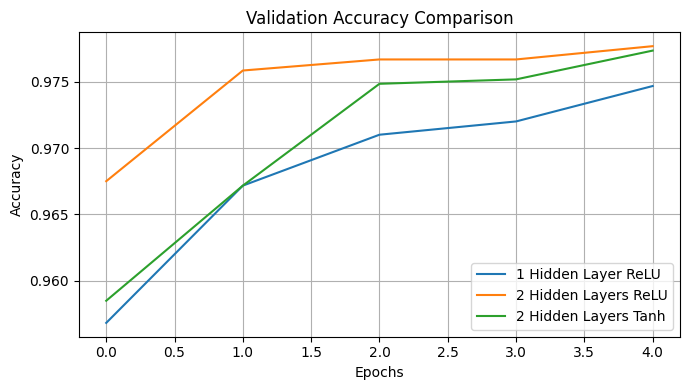

In [5]:
# Step I: Import the libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import to_categorical


# Step II: Load the Local MNIST Dataset
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']


# Step III: Preprocessing

# Flattening + Normalization
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

# One Hot Encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


# Step IV: Model 1 - One Hidden Layer with ReLU
model1 = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history1 = model1.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

print("Model 1 training completed!")


# Step V: Model 2 - Two Hidden Layers with ReLU
model2 = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(264, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

print("Model 2 training completed!")


# Step VI: Model 3 - Two Hidden Layers with Tanh
model3 = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(264, activation='tanh'),
    tf.keras.layers.Dense(128, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history3 = model3.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

print("Model 3 training completed!")


# Step VII: Evaluate Models on Test Data
loss1, acc1 = model1.evaluate(x_test, y_test, verbose=0)
loss2, acc2 = model2.evaluate(x_test, y_test, verbose=0)
loss3, acc3 = model3.evaluate(x_test, y_test, verbose=0)

print("\nModel 1 Accuracy:", acc1 * 100, "%")
print("Model 2 Accuracy:", acc2 * 100, "%")
print("Model 3 Accuracy:", acc3 * 100, "%")

print("\nModel 1 Loss:", loss1)
print("Model 2 Loss:", loss2)
print("Model 3 Loss:", loss3)


# Step VIII: Compare Model Accuracy
models = ['1 Hidden Layer', '2 Hidden Layers ReLU', '2 Hidden Layers Tanh']
accuracy = [acc1 * 100, acc2 * 100, acc3 * 100]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracy)

plt.title("Comparison of Model Accuracy")
plt.xlabel("Model Configuration")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# Step IX: Visualize Loss Curve
plt.figure(figsize=(7, 4))

plt.plot(history1.history['val_loss'], label='1 Hidden Layer ReLU')
plt.plot(history2.history['val_loss'], label='2 Hidden Layers ReLU')
plt.plot(history3.history['val_loss'], label='2 Hidden Layers Tanh')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()


# Step X: Visualize Accuracy Curve
plt.figure(figsize=(7, 4))

plt.plot(history1.history['val_accuracy'], label='1 Hidden Layer ReLU')
plt.plot(history2.history['val_accuracy'], label='2 Hidden Layers ReLU')
plt.plot(history3.history['val_accuracy'], label='2 Hidden Layers Tanh')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 19s 18ms/step - accuracy: 0.9343 - loss: 0.2270 - val_accuracy: 0.9618 - val_loss: 0.1241
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.9727 - loss: 0.0909 - val_accuracy: 0.9721 - val_loss: 0.0881
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.9811 - loss: 0.0616 - val_accuracy: 0.9748 - val_loss: 0.0805
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.9858 - loss: 0.0442 - val_accuracy: 0.9776 - val_loss: 0.0761
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 24s 18ms/step - accuracy: 0.9892 - loss: 0.0332 - val_accuracy: 0.9792 - val_loss: 0.0690
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9911 - loss: 0.0266 - val_accuracy: 0.9767 - val_loss: 0.0816
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.9926 - loss: 0.0223 - val_accuracy: 0.9792 - val_loss: 0.0743
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9938 - loss: 0.0189 - 

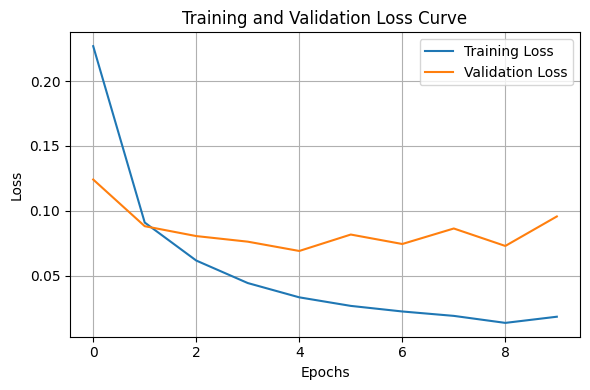

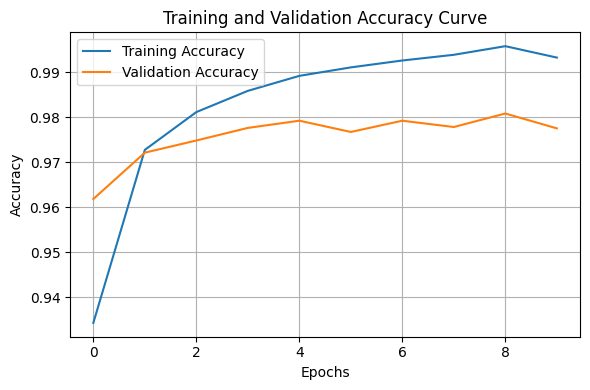

In [7]:

# Step I: Import the libraries
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Step II: Load the Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Step III: Preprocessing

# Flattening + Normalization
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

# One Hot Encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Step IV: Model Configuration
model = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(264, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step V: Model Compilation
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Step VI: Train the Model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

# Step VII: Evaluate the Model
loss, accuracy = model.evaluate(x_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# Step VIII: Testing
predicted = model.predict(x_test[:1])
predicted_class = tf.argmax(predicted[0]).numpy()

print("Predicted Class:", predicted_class)
print("Actual Class:", tf.argmax(y_test[0]).numpy())

# Step IX: Visualize Loss Curve
plt.figure(figsize=(6, 4))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Curve")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

# Step X: Visualize Accuracy Curve
plt.figure(figsize=(6, 4))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy Curve")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9277 - loss: 0.2453 - val_accuracy: 0.9690 - val_loss: 0.1082
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9714 - loss: 0.0932 - val_accuracy: 0.9745 - val_loss: 0.0871
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9804 - loss: 0.0623 - val_accuracy: 0.9720 - val_loss: 0.0941
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9852 - loss: 0.0457 - val_accuracy: 0.9728 - val_loss: 0.0961
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9892 - loss: 0.0338 - val_accuracy: 0.9760 - val_loss: 0.0865
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9906 - loss: 0.0277 - val_accuracy: 0.9800 - val_loss: 0.0765
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9921 - loss: 0.0232 - val_accuracy: 0.9810 - val_loss: 0.0810
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9932 - loss: 0.0197 - val_a

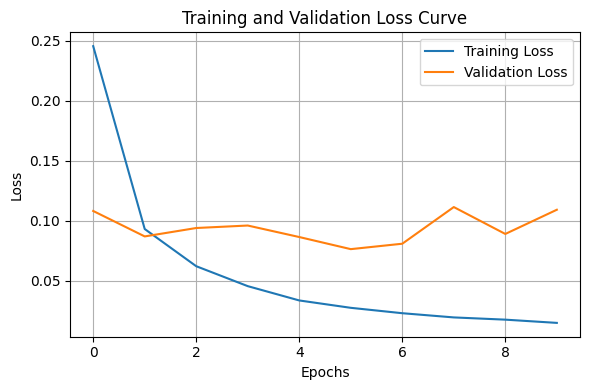

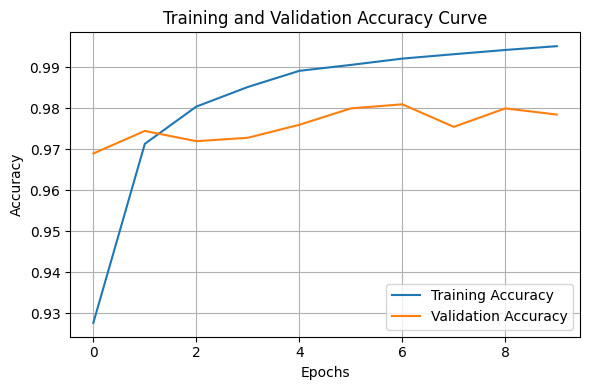

In [ ]:
# Step I: Import the libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import to_categorical

# Step II: Load the Local MNIST Dataset
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

# Step III: Preprocessing

# Flattening + Normalization
 x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

# One Hot Encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Step IV: Model Configuration
model = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(264, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step V: Model Compilation
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Step VI: Train the Model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

# Step VII: Evaluate the Model
loss, accuracy = model.evaluate(x_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# Step VIII: Testing
predicted = model.predict(x_test[:1])
predicted_class = tf.argmax(predicted[0]).numpy()

print("Predicted Class:", predicted_class)
print("Actual Class:", tf.argmax(y_test[0]).numpy())

# Step IX: Visualize Loss Curve
plt.figure(figsize=(6, 4))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Curve")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

# Step X: Visualize Accuracy Curve
plt.figure(figsize=(6, 4))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy Curve")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)
Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.9293 - loss: 0.2428 - val_accuracy: 0.9700 - val_loss: 0.1016
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9711 - loss: 0.0935 - val_accuracy: 0.9787 - val_loss: 0.0797
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9805 - loss: 0.0623 - val_accuracy: 0.9783 - val_loss: 0.0790
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9853 - loss: 0.0465 - val_accuracy: 0.9753 - val_loss: 0.0874
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9878 - loss: 0.0369 - val_accuracy: 0.9813 - val_loss: 0.0687
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9918 - loss: 0.0259 - val_accuracy: 0.9800 - val_loss: 0.0769
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9913 - loss: 0.0243 - val_accuracy: 0.9782 - val_loss: 0.0806
Epoch 8/10
844/844 ━━━━━━━━━━

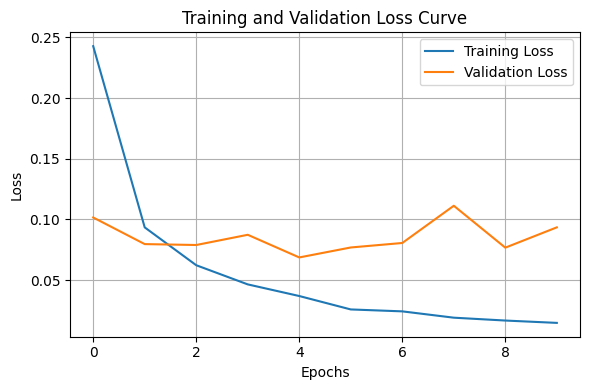

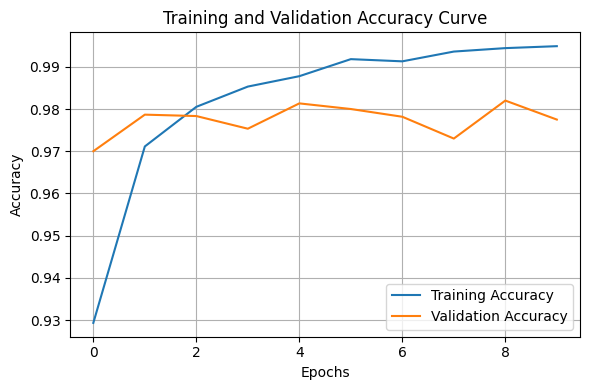

In [4]:
# Step I: Import the libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import struct

from tensorflow.keras.utils import to_categorical


# Step II: Load the Local MNIST Dataset

# Load Images
def load_images(file):
    with open(file, 'rb') as f:
        magic, num, rows, cols = struct.unpack('>IIII', f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)

    return images.reshape(num, rows, cols)


# Load Labels
def load_labels(file):
    with open(file, 'rb') as f:
        magic, num = struct.unpack('>II', f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)

    return labels


# Load Dataset
x_train = load_images('MNIST/train-images-idx3-ubyte')
y_train = load_labels('MNIST/train-labels-idx1-ubyte')

x_test = load_images('MNIST/t10k-images-idx3-ubyte')
y_test = load_labels('MNIST/t10k-labels-idx1-ubyte')

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)


# Step III: Preprocessing

# Flattening + Normalization
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

# One Hot Encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


# Step IV: Model Configuration
model = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(264, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])


# Step V: Model Compilation
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# Step VI: Train the Model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)


# Step VII: Evaluate the Model
loss, accuracy = model.evaluate(x_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")


# Step VIII: Testing
predicted = model.predict(x_test[:1])
predicted_class = tf.argmax(predicted[0]).numpy()

print("Predicted Class:", predicted_class)
print("Actual Class:", tf.argmax(y_test[0]).numpy())


# Step IX: Visualize Loss Curve
plt.figure(figsize=(6, 4))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Curve")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()


# Step X: Visualize Accuracy Curve
plt.figure(figsize=(6, 4))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy Curve")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()